# Example: Analysis of Put Credit Vertical Spreads
In this example, we will analyze vertical bullish credit spreads. These are directional options strategies that involve selling a higher strike put and buying a lower strike put, the high-strike is near the money and the low-strike is out of the money.

> __Learning Objectives:__
> 
> By the end of this example, you will be able to:
> * __Construct profit diagrams for put vertical spreads:__ Build profit and loss profiles for put credit spreads by combining short and long put contracts with different strike prices, and compute the breakeven point where the position transitions from profit to loss.
> * __Calculate probability of profit and probability of exercise for vertical spreads:__ Use cumulative distribution functions of projected share price distributions to determine the likelihood of profit at the breakeven point, and each leg's probability of exercise, under our belief $\mathbb{P}$ and the risk-neutral probabilities $\mathbb{Q}$.
> * __Compute Delta for composite positions to assess hedging requirements:__ Calculate the composite Delta of a put vertical spread by summing the weighted Deltas of its legs on the Leisen–Reimer tree, compare the leg Deltas with the CRR tree and the quoted Deltas, and find the number of shares that makes the position delta-neutral.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load the options data using [the `MyOptionsChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsChainDataSet) and store the metadata in the `metadata::Dict{String,Any}` variable and the options chain data in the `optionschain::DataFrame` variable.

In [2]:
metadata, optionschain = let
    
    # initialize -
    options_dataset = MyOptionsChainDataSet(ticker="amd-2026");
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

What's in the `metadata::Dict{String,Any}` dictionary?

In [3]:
metadata |> keys

KeySet for a Dict{String, Any} with 10 entries. Keys:
  "DTE"
  "purchase_date"
  "historical_volatility"
  "underlying_share_price_ask"
  "source"
  "underlying_share_price_bid"
  "is_weekly"
  "atm_IV"
  "expiration_date"
  "underlying_share_price_mid"

What about the `optionschain::DataFrame` variable?

In [4]:
optionschain

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
1,5.0,0.9906,524.2,526.53,528.85,517.3,0,"1,074",5.2163,0.9996,Call
2,10.0,0.9812,518.9,521.4,523.9,479.51,0,4,3.7202,0.9998,Call
3,15.0,0.9718,514.3,516.63,518.95,0.0,0,0,3.8539,0.9992,Call
4,20.0,0.9624,509.3,511.63,513.95,466.97,0,956,3.4532,0.9992,Call
5,25.0,0.953,504.1,506.55,509.0,427.94,0,212,2.9877,0.9994,Call
6,30.0,0.9436,499.6,501.83,504.05,457.14,0,208,3.167,0.9986,Call
7,35.0,0.9342,494.65,496.85,499.05,479.33,0,9,2.9794,0.9985,Call
8,40.0,0.9247,488.4,491.17,493.95,483.4,1,13,1.9981,0.9999,Call
9,45.0,0.9153,484.25,486.7,489.15,425.63,0,101,2.4434,0.9991,Call


### Constants
Let's set the constants. The share price $S_{0}$ is AMD's close on the quote date. The step size `Δt::Float64` is one day in units of years (a `365-day` year), and `T::Float64` is the time to expiration. The risk-free rate $g_{y}$ is the 13-week Treasury bill yield on the quote date, converted to continuous compounding, and `𝒟::Float64` is the accumulation factor $\mathcal{D}_{T,0}(g_{y})=e^{g_{y}T}$ from today to expiration.

In [5]:
Sₒ = metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # close on the quote date, 2026-10-26 (USD/share)

Other constants:

In [6]:
Δt = (1/365); # one calendar day, expressed in years
DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (days)
T = DTE*Δt; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates; update it if you change the quote date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*T); # accumulation factor from today to expiration (dimensionless)

In this example, we'll need to do a projection of the future share price distribution at the contract's expiration date. We'll use a Geometric Brownian Motion (GBM) model to project the future share price distribution at expiration.

Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and diffusion coefficients for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [7]:
parameters_df = let

    # load -
    df = CSV.read(joinpath(_PATH_TO_DATA,"SAGBM-Parameters-Fall-2025.csv"), DataFrame);
    df; # return
end;

We are looking at `AMD`, so let's see what the parameters for this ticker are:

In [8]:
filter(:ticker=> x-> x=="AMD", parameters_df)

Row,ticker,drift,t,lower_bound_drift,upper_bound_drift,volatility
,String7,Float64,Float64,Float64,Float64,Float64
1,AMD,0.439658,1.96082,0.43459,0.444725,0.474283


### Contract models
Next, we construct contract models for the options in this example. We begin by building an instance of the [MyAmericanPutContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel) using the [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanPutContractModel},%20NamedTuple}). 

The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanPutContractModel},%20NamedTuple}) takes two arguments: the type to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price `K`, the `premium` paid for the option, the days to expiration `DTE` (units: years), the `sense` parameter (1 for long, -1 for short), the number of contracts in the `copy` field and the implied volatility in the `IV` field.

We save the __short__ put option contract model, at the higher strike price $K_{2}$, in the `put_contract_model_short::MyAmericanPutContractModel` variable:

In [9]:
put_contract_model_short = let

    # initialize -
    K = 520.0; # strike price of the short put, K₂ (USD/share)
    options_dataset =  optionschain;
    premium = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:Mid];
    IV = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:IV]; # implied volatility (decimal)
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    θ = -1; # short position
    

    # build the contract model -
    put_option_model = build(MyAmericanPutContractModel, (
        K = K, 
        premium = premium, # mark price
        DTE = DTE*Δt, # units: years
        sense = θ,
        copy = 1,
        IV = IV
    ));

    put_option_model; # return the model -
end

MyAmericanPutContractModel(520.0, -1, 0.1452054794520548, 0.5619, 38.1, nothing, 1)

Next, let's build the __long__ put option contract model for the lower strike price $K_{1}$ in the vertical spread. Let's save the long put option contract model in the `put_contract_model_long::MyAmericanPutContractModel` variable:

In [10]:
put_contract_model_long = let

    # initialize -
    K = 500.0; # strike price of the long put, K₁ (USD/share)
    options_dataset =  optionschain;
    premium = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:Mid];
    IV = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:IV]; # implied volatility (decimal)
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    θ = 1; # long position

    # build the contract model -
    put_option_model = build(MyAmericanPutContractModel, (
        K = K, 
        premium = premium, # mark price
        DTE = DTE*Δt, # units: years
        sense = θ,
        copy = 1,
        IV = IV
    ));

    put_option_model; # return the model -
end

MyAmericanPutContractModel(500.0, 1, 0.1452054794520548, 0.5669, 29.35, nothing, 1)

___

## Task 1: Compute Profit, Loss and Breakeven Points
In this task, we compute the profit and loss (P&L) profile for the vertical credit spread position at expiration, as well as the breakeven point.

A put vertical spread is constructed by combining 2 $\times$ put contracts, a short put contract generates income while the long put contract controls downside risk. This trade has a bullish outlook on the underlying asset.

> __Bullish put credit spread:__
>
> Let's build a bullish put credit spread for AMD whose current share price is $S(0) = 531.26$ USD/share. This trade structure is constructed by buying (long) a put with strike $K_{1}$ and selling (short) a put with the higher strike $K_{2}$.
>
> * Leg 1: The strike price for the long put leg is given by $K_{1}$ = 500 USD/share with DTE = 53 days
> * Leg 2: The strike price for the short put leg is given by $K_{2}$ = 520 USD/share with DTE = 53 days
>
> This trade will generate a net credit when opened. Depending on the share price at expiration, the trade can result in a profit or loss. The maximum profit occurs when the share price at expiration is above the higher strike price $K_{2}$. The maximum loss occurs when the share price at expiration is below the lower strike price $K_{1}$.


### Profit and Breakeven Analysis for Put Vertical Spread
Let contract $i$ have a strike price of $K_{i}$ and premium $\mathcal{P}_{i}$, numbered from low to high: contract 1 is the long leg ($\theta_{1} = 1$) and contract 2 the short leg ($\theta_{2} = -1$), where $K_{1} < K_{2} < S_{0}$. The share price at expiration is given by $S(T)$, and $\mathcal{D}_{T,0}(g_{y})$ is the accumulation factor from today to expiration. Then, the profit for a single put vertical spread at expiration is given by:

$$
\hat{P}_{\mathcal{C}} = \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{2} - \mathcal{P}_{1}\right) - \left(K_{2} - S(T)\right)^{+} + \left(K_{1} - S(T)\right)^{+}
$$

where $V_{p}(K,S(T)) = (K-S(T))^{+}=\max(K-S(T),0)$ is the payoff function for a put contract. The first term is the net premium received, grown to expiration, and the others are the leg payoffs. The maximum possible profit, loss, and breakeven conditions are given by:

* The maximum possible profit of $\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{2} - \mathcal{P}_{1}\right)$ will occur when $S(T)\geq{K_{2}}$.
* The maximum possible loss of $\left(K_{2} - K_{1}\right) - \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{2} - \mathcal{P}_{1}\right)$ will occur when $S(T)\leq{K_{1}}$.
* The put credit spread will breakeven when $S(T) = S^{\ddagger} = K_{2}-\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{2} - \mathcal{P}_{1}\right)$.

Let's visualize the profit at expiration:

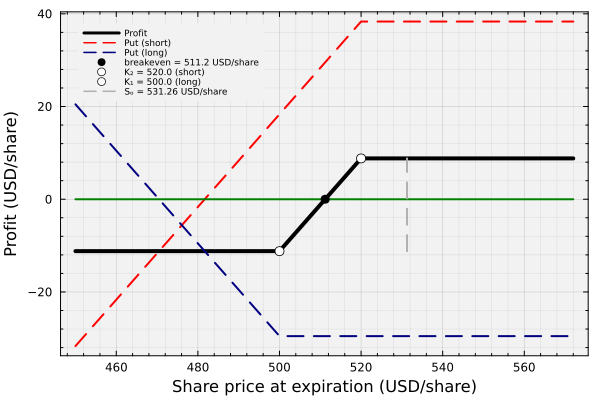

In [11]:
let

    # initialize: leg 1 is the long put at K₁, leg 2 the short put at K₂ -
    premium_1 = put_contract_model_long.premium; # 𝒫₁ (USD/share)
    premium_2 = put_contract_model_short.premium; # 𝒫₂ (USD/share)
    K₁ = put_contract_model_long.K;
    K₂ = put_contract_model_short.K;
    credit = 𝒟*(premium_2 - premium_1); # credit grown to expiration (USD/share)
    max_profit = credit; # for S(T) ≥ K₂ (USD/share)
    max_loss = (K₂ - K₁) - credit; # for S(T) ≤ K₁, a positive number (USD/share)
    breakeven = K₂ - credit; # S‡ (USD/share)

    S = range(0.9*K₁,stop = 1.1*K₂, step=0.1) |> collect;
    number_of_steps = length(S);
    BEL = zeros(length(S))
    profit_array = profit([put_contract_model_short, put_contract_model_long], S; 𝒟 = 𝒟); # premiums grown to expiration

    plot(profit_array[:,1], profit_array[:,4], lw=4, label="Profit", c=:black,
        bg="gray95", 	background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(profit_array[:,1], profit_array[:,2], lw=2, label="Put (short)", ls=:dash, c=:red)
    plot!(profit_array[:,1], profit_array[:,3], lw=2, label="Put (long)", ls=:dash, c=:navyblue)

    plot!(S,BEL,lw=2, c=:green, label="")
    scatter!([breakeven], [0], c=:black, label="breakeven = $(round(breakeven, digits = 2)) USD/share", ms=5)
    scatter!([K₂],[max_profit], ms=5, label = "K₂ = $(K₂) (short)", msc=:black, mc=:white)
    scatter!([K₁],[-max_loss], ms=5, label = "K₁ = $(K₁) (long)", msc=:black, mc=:white)

    VLINE = zeros(number_of_steps, 2)
    VLINE[:,1] .= Sₒ*ones(number_of_steps)
    VLINE[:,2] .= range(minimum(profit_array[:,end]), stop = maximum(profit_array[:,end]), length = number_of_steps) |> collect;
    plot!(VLINE[:,1], VLINE[:,2], lw=2, c= :gray69, ls=:dash,
        label="Sₒ = $(Sₒ) USD/share", xminorticks=true, yminorticks=true, minorgrid=true, legendfontsize=6)

    xlabel!("Share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit (USD/share)", fontsize=18)
end

The breakeven point can be calculated by setting the profit function equal to zero and solving for $S(T)$. Let's show it with the maximum profit and the maximum loss:

In [12]:
breakeven = let

    # initialize: leg 1 is the long put at K₁, leg 2 the short put at K₂ -
    premium_1 = put_contract_model_long.premium; # 𝒫₁ (USD/share)
    premium_2 = put_contract_model_short.premium; # 𝒫₂ (USD/share)
    K₂ = put_contract_model_short.K;
    K₁ = put_contract_model_long.K;
    credit = 𝒟*(premium_2 - premium_1); # credit grown to expiration (USD/share)
    breakeven = K₂ - credit; # S‡ (USD/share)

    # show the maximum profit, the breakeven, and the maximum loss -
    df = DataFrame(quantity = ["maximum profit, S(T) ≥ K₂", "breakeven S‡", "maximum loss, S(T) ≤ K₁"],
        value = [credit, breakeven, (K₂ - K₁) - credit], units = ["USD/share", "USD/share", "USD/share"]);
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    breakeven; # return
end;

 --------------------------- -------- -----------
  quantity                     value   units     
 --------------------------- -------- -----------
  maximum profit, S(T) ≥ K₂     8.80   USD/share
  breakeven S‡                511.20   USD/share
  maximum loss, S(T) ≤ K₁      11.20   USD/share
 --------------------------- -------- -----------


___

## Task 2: Compute the Probability of Profit (POP) and the Probability of Exercise (POE)
In this task, we compute the Probability of Profit (POP) of the put credit spread and the Probability of Exercise (POE) of each leg at expiration.

To start, we simulate share prices at expiration under the risk-neutral probabilities $\mathbb{Q}$: geometric Brownian motion with drift $g_{y}$ and the at-the-money implied volatility. Later, we compare the probabilities with our belief $\mathbb{P}$, built from the SAGBM parameters we loaded earlier.

We'll save the GBM model in the `model::MyGeometricBrownianMotionEquityModel` variable:

In [13]:
model = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # at-the-money implied volatility on the quote date (decimal)

    # risk-neutral ℚ: drift = risk-free rate, volatility = at-the-money implied volatility -
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = gᵧ,
        σ = ATM_IV
    ));

    model; # return
end

MyGeometricBrownianMotionEquityModel(0.04128677804517802, 0.5617)

Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding the `AMD` data, let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices corresponding to the duration of the contract, i.e., $T_{2} = \text{DTE}$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint_samples::Array{Float64,1}` variable.

So what do we get?

In [14]:
endpoint_samples = let

    # initialize
    Random.seed!(5660); # reproducible samples
    number_of_samples = 50000; # how many samples do we want to generate?

    # compute the endpoint samples -
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0,
        T₂ = T,
        Δt = Δt,
        Sₒ = Sₒ
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    println("The mean projected price for GBM: $(mean(endpoint))");

    endpoint; # return
end;

The mean projected price for GBM: 534.7787839167826


#### Check: Are future GBM share prices log-normally distributed?
We expect geometric Brownian motion to generate __log-normally distributed__ share prices. We can check this expectation by performing an [exact one-sample Kolmogorov-Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#Kolmogorov-Smirnov-test) on the samples and the log-normal distribution that geometric Brownian motion predicts.
> __Hypothesis:__ The `H0:null hypothesis` for the test is the data (endpoint samples generated using geometric Brownian motion) comes from the LogNormal distribution `d_gbm`. The alternative hypothesis `H1:alternative` is the samples are not drawn from `d_gbm`.

Under geometric Brownian motion, $\ln S(T)$ is normal with mean $\ln S_{0}+(\mu-\sigma^{2}/2)T$ and standard deviation $\sigma\sqrt{T}$. Let's build this [LogNormal distribution exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) and save it in the `d_gbm::LogNormal` variable:

In [15]:
d_gbm = LogNormal(log(Sₒ) + (model.μ - model.σ^2/2)*T, model.σ*sqrt(T)); # distribution of S(T) under GBM

Next, execute [the exact one-sample Kolmogorov–Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ExactOneSampleKSTest) and check the [pvalue](https://en.wikipedia.org/wiki/P-value). A large p-value means we fail to reject the `H0:null hypothesis`: the `endpoint_samples` are consistent with `d_gbm`.

In [16]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm)

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.00342404

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.6009

Details:
    number of observations:   50000


`Unhide` the code block below to see how we plotted the future share price of `AMD` generated using a risk-neutral single asset geometric Brownian motion model parameterized using the implied volatility.
> __What do we see?__ The geometric Brownian motion generates future share prices that are [log-normally distributed](https://en.wikipedia.org/wiki/Log-normal_distribution) (blue line), and the log-normal distribution `d_gbm` (red line) describes them, consistent with the check above.

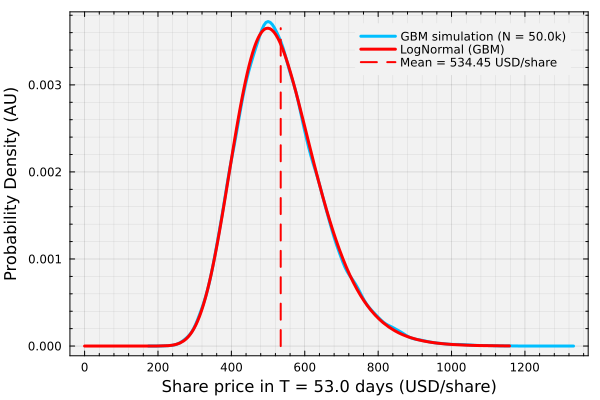

In [17]:
let

    # setup the mean line (for plotting) -
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    LX = ones(100) .* mean(d_gbm);
    LY = range(0, stop = maximum(pdf.(d_gbm, range(quantile(d_gbm,0.01), stop=quantile(d_gbm,0.99), length=100))), length = 100) |> collect;

    # plot -
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, xminorgrid = true, yminorgrid = true)
    
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_gbm),digits=2)) USD/share")
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
Alternatively, we could use the __implied volatility__ to estimate the expected share price move over the time to expiration $T$ (years).
Suppose we construct a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ whose mean $\mu_{IV} = S_{0}\exp(g_{y}T)$ is the share price grown at the risk-free rate, or just $\mu_{IV}\approx{S}_{0}$ for short duration contracts, and whose standard deviation $\sigma_{IV}$ is:
$$
\sigma_{IV} = S_{0}\cdot\text{IV}\cdot\sqrt{T}
$$
where IV is the at-the-money implied volatility (decimal). We use the [Normal type exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal). This is only an approximate model of the future share price; it has a couple of issues: 
> __Watch out!__ This model assumes a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal), which is problematic because it can emit negative share prices. One way to fix this issue is to use a [Truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) instead.

However, despite the potential issues, this model is __widely__ used to generate quick estimates of future share price ranges using the forward-looking implied volatility. Let's save the Normal IV distribution $\mathcal{N}(\mu_{IV},\sigma_{IV})$ in the `d_IV::Normal` variable:

In [18]:
d_IV = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # at-the-money implied volatility on the quote date (decimal)
    
    # build the Normal model -
    d = Normal(Sₒ*exp(gᵧ*T), Sₒ*ATM_IV*sqrt(T)); # mean: Sₒ grown at gᵧ; standard deviation: Sₒ⋅IV⋅√T
    d; # return

end

Normal{Float64}(μ=534.4545050434095, σ=113.71114807827765)

`Unhide` the code block below to see how we plotted the `d_gbm::LogNormal` and `d_IV::Normal` future share price densities at `T = 53 days`.  

> __What do we see?__ The log-normal GBM share price distribution (blue line) is right-skewed and cannot admit negative share prices. However, the Normal IV distribution (red line) is symmetric around the mean future share price and can admit negative share prices, albeit with a small probability.

How do the two distributions compare?

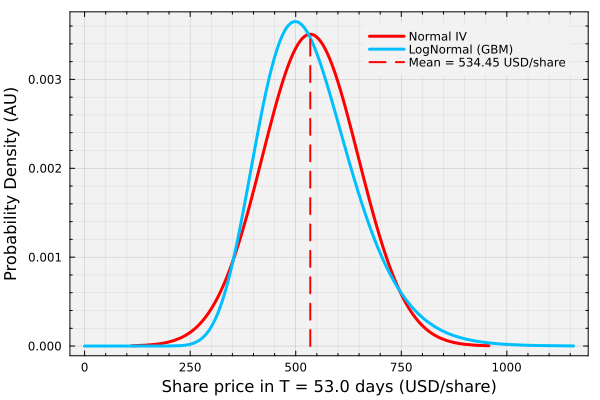

In [19]:
let

    # initialize -
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    LX = ones(100) .* mean(d_IV);
    LY = range(0, stop = maximum(pdf.(d_IV, range(quantile(d_IV,0.01), stop=quantile(d_IV,0.99), length=100))), length = 100) |> collect;

    plot(d_IV, lw=3, label="Normal IV", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, minorgrid = true);
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:deepskyblue1)
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_IV),digits=2)) USD/share")
    
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Probability of Profit (POP)
The POP for a put credit spread is the probability that the future share price at expiration $S(T)$ is larger than the breakeven point $S^{\ddagger}$:
$$
\begin{align*}
\text{POP} &= \mathbb{P}(S(T) > S^{\ddagger}) \\
& = 1 - F_{S}(S^{\ddagger})
\end{align*}
$$
where $F_{S}(x)$ is the cumulative distribution function (CDF) of the future share price at expiration, i.e., $F_{S}(x) = \mathbb{P}(S(T) \leq x)$.

### Probability of Exercise (POE)
The long put is exercised if the share price at expiration is below its strike price, $S(T)<K_{1}-0.01$, and the short put if $S(T)<K_{2}-0.01$. Since $K_{1}<K_{2}$, if the long put finishes in the money, so does the short put:
$$
\text{POE}_{1} = F_{S}(K_{1}-0.01) \qquad \text{POE}_{2} = F_{S}(K_{2}-0.01)
$$

Let's compute the POP and each leg's POE for three distributions of the share price at expiration:
* __Our belief $\mathbb{P}$:__ log-normal, with drift $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$ and volatility $\hat{\sigma}$, where $\hat{\mu}_{g}$ (the `drift` column) and $\hat{\sigma}$ (the `volatility` column) are the AMD estimates we loaded earlier.
* __Risk-neutral $\mathbb{Q}$:__ log-normal, with drift $g_{y}$ and the at-the-money implied volatility, the distribution `d_gbm` above.
* __Normal IV:__ the quick approximation `d_IV` above, close to $\mathbb{Q}$ but not log-normal.

So what do we get?

In [20]:
let

    # initialize: the three share price distributions at expiration -
    K₁ = put_contract_model_long.K; # long put (USD/share)
    K₂ = put_contract_model_short.K; # short put (USD/share)
    amd = only(eachrow(filter(:ticker => ==("AMD"), parameters_df))); # AMD's SAGBM estimates
    μ̂_g = amd.drift; # mean growth rate (1/yr)
    σ̂ = amd.volatility; # historical volatility (1/sqrt(yr))
    μ̂ = μ̂_g + σ̂^2/2; # GBM drift of our belief ℙ (1/yr)
    cases = [
        ("our belief ℙ", LogNormal(log(Sₒ) + (μ̂ - σ̂^2/2)*T, σ̂*sqrt(T))),
        ("risk-neutral ℚ", d_gbm),
        ("Normal IV (approximates ℚ)", d_IV)
    ];

    # the seller's POP above the breakeven, and each leg's POE -
    df = DataFrame(case = String[], POP = Float64[], POE_short = Float64[], POE_long = Float64[]);
    for (label, d) ∈ cases
        push!(df, (label, 1 - cdf(d, breakeven), cdf(d, K₂ - 0.01), cdf(d, K₁ - 0.01)));
    end
    pretty_table(df; column_labels = ["distribution of S(T)", "POP", "POE short put, K₂", "POE long put, K₁"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
    println("our belief ℙ: μ̂_g = $(round(μ̂_g, digits = 4)), σ̂ = $(round(σ̂, digits = 4)), μ̂ = $(round(μ̂, digits = 4)) (1/yr)");
    println("risk-neutral ℚ: gᵧ = $(round(gᵧ, digits = 4)) (1/yr), ATM IV = $(model.σ)");

    # checks: the ℚ row is d_gbm; the breakeven sits below K₂, so POP > 1 - POE of the short put -
    @assert isapprox(df.POE_short[2], cdf(d_gbm, K₂ - 0.01); atol = 1e-12) "the ℚ row does not match d_gbm"
    @assert all(df.POP .> 1 .- df.POE_short) "the POP should exceed 1 - POE of the short put"
end

 ---------------------------- -------- ------------------- ------------------
  distribution of S(T)            POP   POE short put, K₂   POE long put, K₁ 
 ---------------------------- -------- ------------------- ------------------
  our belief ℙ                 0.7144              0.3185             0.2454
  risk-neutral ℚ               0.5402              0.4916             0.4190
  Normal IV (approximates ℚ)   0.5810              0.4494             0.3809
 ---------------------------- -------- ------------------- ------------------
our belief ℙ: μ̂_g = 0.4397, σ̂ = 0.4743, μ̂ = 0.5521 (1/yr)
risk-neutral ℚ: gᵧ = 0.0413 (1/yr), ATM IV = 0.5617


> __What do we see?__
>
> * __The POP:__ Our belief $\mathbb{P}$ gives the spread a much higher POP than $\mathbb{Q}$. Its drift $\hat{\mu}$ is much larger than $g_{y}$, and its volatility $\hat{\sigma}$ is lower than the implied volatility, so $\mathbb{P}$ puts less probability below the breakeven.
> * __The POE:__ In every row, the short put is more likely to be exercised than the long put, because its strike price is higher. Under $\mathbb{Q}$, the short put finishes in the money about half the time.
> * __POP and POE:__ In every row, the POP is larger than one minus the short put's POE. The breakeven sits below $K_{2}$, so the spread still makes money when the share price finishes just below $K_{2}$.

___

## Task 3: Is this trade Delta-neutral?
In this task, we compute the composite Delta of the put credit spread when we open it, and the number of shares that would make the position delta-neutral.

With one copy of each leg, the composite Delta of the spread, per share, is the sum of the legs' Deltas weighted by their orientation:
$$
\Delta_{\mathcal{C}} = \theta_{1}\Delta_{1} + \theta_{2}\Delta_{2} = \Delta_{1} - \Delta_{2}
$$
where $\Delta_{i}$ is the Delta of a long put at strike $K_{i}$. A positive $\Delta_{\mathcal{C}}$ means the position gains when the share price rises. The shares that make one spread delta-neutral are $N_{S} = -m\,\Delta_{\mathcal{C}}$, with $m = 100$ shares per contract.

We estimate each leg's Delta by a central difference on the Leisen–Reimer tree, repricing with the share price moved up and down by $\epsilon_{S}=0.01\,S_{0}$, using [the `𝒫(...)` function](src/Helper.jl) on a tree with $h=20\cdot\text{DTE}+1$ levels (odd, about twenty per day). For comparison, we also compute it on the CRR tree with $h$ and $h+1$ levels, because CRR estimates move back and forth between odd and even numbers of levels, and we show the archive's quoted Delta. Every Delta in the table is the Delta of a long put, before the orientation is applied. So what do we get?

In [21]:
delta_table = let

    # initialize -
    h = 20*round(Int, DTE) + 1; # odd number of tree levels, about twenty per day
    ε_S = 0.01*Sₒ; # share price step (USD/share)
    legs = [("put at K₁ (long leg)", put_contract_model_long), ("put at K₂ (short leg)", put_contract_model_short)];

    # each leg's Delta as a long contract: Leisen–Reimer, CRR with h and h + 1 levels, and the archive's quote -
    df = DataFrame(leg = String[], K = Float64[], Δ_LR = Float64[], Δ_CRR_h = Float64[], Δ_CRR_h1 = Float64[], Δ_quote = Float64[]);
    for (label, model) ∈ legs
        σ = model.IV; # this leg's implied volatility (decimal)
        Δ_LR = (𝒫(model; S = Sₒ + ε_S, σ = σ, T = T, g = gᵧ, h = h) -
            𝒫(model; S = Sₒ - ε_S, σ = σ, T = T, g = gᵧ, h = h))/(2*ε_S);
        Δ_CRR = [(binomial_premium(model; method = :crr, h = n, Sₒ = Sₒ + ε_S, σ = σ, T = T, μ = gᵧ) -
            binomial_premium(model; method = :crr, h = n, Sₒ = Sₒ - ε_S, σ = σ, T = T, μ = gᵧ))/(2*ε_S) for n ∈ (h, h + 1)];
        Δ_quote = filter([:Strike,:Type] => (x,y) -> (x == model.K && y == "Put"), optionschain)[1,:Delta];
        push!(df, (label, model.K, Δ_LR, Δ_CRR[1], Δ_CRR[2], Δ_quote));
    end
    pretty_table(df; column_labels = ["leg (Delta of a long put)", "K (USD/share)", "Leisen–Reimer", "CRR, h = $(h)", "CRR, h = $(h + 1)", "archive quote"],
        alignment = [:l, :r, :r, :r, :r, :r], formatters = [fmt__printf("%.4f", [3, 4, 5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);

    # checks: a long put's Delta is between -1 and 0 -
    @assert all(-1 .≤ df.Δ_LR .≤ 0) "a put Delta is outside [-1, 0]"

    df; # return
end;

 --------------------------- --------------- --------------- --------------- --------------- ---------------
  leg (Delta of a long put)   K (USD/share)   Leisen–Reimer   CRR, h = 1061   CRR, h = 1062   archive quote 
 --------------------------- --------------- --------------- --------------- --------------- ---------------
  put at K₁ (long leg)                500.0         -0.3405         -0.3410         -0.3401         -0.3406
  put at K₂ (short leg)               520.0         -0.4097         -0.4107         -0.4089         -0.4099
 --------------------------- --------------- --------------- --------------- --------------- ---------------


Now let's compute the composite Delta of the spread and the shares that make it delta-neutral, using the Leisen–Reimer Deltas:

In [22]:
let

    # initialize: Δ_𝒞 = θ₁Δ₁ + θ₂Δ₂ with θ₁ = 1 (long put at K₁) and θ₂ = -1 (short put at K₂) -
    m = 100; # shares per contract
    Δ₁ = delta_table.Δ_LR[1]; # Delta of a long put at K₁
    Δ₂ = delta_table.Δ_LR[2]; # Delta of a long put at K₂ (we are short this leg)
    Δ_𝒞 = Δ₁ - Δ₂; # composite Delta of the spread (per share)
    N_S = -m*Δ_𝒞; # shares that make one spread delta-neutral

    # show the results -
    println("Composite Delta of the spread (per share), Δ_𝒞 = Δ₁ - Δ₂ = $(round(Δ_𝒞, digits = 4))");
    println("Shares that make one spread delta-neutral, N_S = -100⋅Δ_𝒞 = $(round(N_S, digits = 2))");
    println(N_S < 0 ? "The spread gains when the share price rises, so we would sell (short) $(round(-N_S, digits = 1)) shares to hedge it." :
        "The spread gains when the share price falls, so we would buy $(round(N_S, digits = 1)) shares to hedge it.");
end

Composite Delta of the spread (per share), Δ_𝒞 = Δ₁ - Δ₂ = 0.0692
Shares that make one spread delta-neutral, N_S = -100⋅Δ_𝒞 = -6.92
The spread gains when the share price rises, so we would sell (short) 6.9 shares to hedge it.


> __What do we see?__
>
> * __Leisen–Reimer and the quotes:__ The Leisen–Reimer Deltas match the archive's quoted Deltas to about three decimal places. The CRR Deltas with $h$ and $h+1$ levels sit on either side of them.
> * __The spread is nearly delta-neutral:__ The two legs' Deltas nearly cancel, so the spread's composite Delta is small and positive. It gains a little when the share price rises, as a bullish position should, and hedging one spread takes selling only a few shares.

___

## Summary
In this example, we built a put credit spread on AMD, computed its profit at expiration and breakeven, its probability of profit and each leg's probability of exercise under our belief and under the risk-neutral probabilities, and its composite Delta.

> __Key Takeaways:__
>
> * __Put vertical spreads have defined risk and reward boundaries:__ We computed the maximum profit as the net credit grown to expiration, earned when the share price stays above the higher strike, and the maximum loss as the difference between the strike prices minus that credit, reached when the share price falls below the lower strike.
> * __Probability measures assess position risk from different perspectives:__ We computed the probability of profit above the breakeven and each leg's probability of exercise under our belief $\mathbb{P}$ and under the risk-neutral probabilities $\mathbb{Q}$. Our belief's large drift and lower volatility gave a much higher probability of profit than $\mathbb{Q}$, and in every case the short put was more likely to be exercised than the long put.
> * __Delta indicates directional exposure and hedging requirements:__ We computed each leg's Delta on the Leisen–Reimer tree, which matched the quoted Deltas, and summed them with their orientations. The spread's composite Delta was small and positive, so it gains a little when the share price rises, and selling a few shares per spread makes it delta-neutral.

Understanding put vertical spreads enables traders to generate income while limiting downside risk in bullish market conditions.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.